# NICER timing: periodograms, folded profiles and the pulse template

Reproduces the NICER panels of the paper (Section 3 and the template of Section 5):

| cell | paper item | file |
|---|---|---|
| Observation summary | Table 1 (NICER rows) | `results/nicer_timing.json` |
| $Z^2$ periodograms | Figure 1 (top row), Table 2 (NICER rows) | `nicer_z2_2021a.pdf`, `nicer_z2_2021b.pdf`, `nicer_z2_2024.pdf` |
| Combined 2021 periodograms | Figure 9 (top left, top right) | `nicer_z2_2021combined.pdf`, `nicer_z2_hires_2021.pdf` |
| Folded soft/hard profiles | Figure 2 (top row) | `nicer_folded_softhard_{2021a,2021b,2024}.pdf` |
| Hardness ratio of the 2024 profile | Figure 3 | `nicer_folded_hr_2024.pdf` |
| Pulse template | Figure 6 | `nicer_2021a_phases_template.pdf` |

Inputs: HENDRICS event files and SCORPEON background light curves (`src/config.py`).

In [1]:
import sys
sys.path.insert(0, '../src')

import json
import numpy as np
from stingray.pulse import z_n_search
from pint.templates.lctemplate import prim_io, LCTemplate

import config
from data_io import load_nicer_events, load_nicer_background, nicer_summary, phase_centers
from timing_analysis import fold, fold_lightcurve, get_frequency_uncertainty
from statistics import calculate_hardness_ratio, test_hardness_ratio_variability
import plotting

savedir = config.FIGURE_DIR
labels = {'4592010200': '2021a', '4592010300': '2021b', '7656010100': '2024', '4592010000': '2021combined'}
results = {}

## Load the event lists (0.3-7 keV for 2021A, 0.3-10 keV otherwise) and the background light curves

In [2]:
events = {obs: load_nicer_events(obs) for obs in labels}
bkg = {obs: load_nicer_background(obs) for obs in config.NICER_OBS}

/opt/miniconda3/envs/CTCV_PINT/lib/python3.13/site-packages/stingray/lightcurve.py:245: UserWarning: Unrecognized keywords: ['extname', 'date-obs', 'time-obs', 'date-end', 'time-end', 'tstart', 'tstop', 'deltat', 'ra_nom', 'dec_nom', 'telescop', 'timesys', 'timezero', 'timeunit', 'mjdrefi', 'mjdreff', 'equinox', 'radecsys', 'creator', 'origin', 'date', 'checksum', 'datasum', 'history', 'lastpcol', 'observer', 'title', 'ra_obj', 'dec_obj', 'obs_id', 'targ_id', 'seqpnum', 'object', 'procver', 'softver', 'caldbver', 'tlm2fits', 'leapinit', 'nimkflev', 'nipf2ver', 'vehfile', 'imanfile', 'robofile', 'timedel', 'timepixr', 'phalcut', 'phahcut', 'hduclass', 'hduclas1', 'hduclas2', 'hduclas3', 'nibkgc1', 'nibkgc2', 'nibkgc3', 'nibkgc4', 'nibkgc5', 'nibkgc6', 'nibkgncl', 'nibkgtot', 'nibkgerr', 'nibkgtyp', 'scorpver', 'scorpcom', 'scorpvar', '']
  warnings.warn(f"Unrecognized keywords: {list(other_kw.keys())}")
/opt/miniconda3/envs/CTCV_PINT/lib/python3.13/site-packages/stingray/lightcurve.py:2

## Table 1 (NICER rows): good time, time span and background-subtracted counts

In [3]:
results['table1'] = {}
for obs, name in config.NICER_OBS.items():
    s = nicer_summary(events[obs], bkg[obs])
    results['table1'][name] = s
    print(f"{name}: good time {s['good_time_ks']:.2f} ks, span {s['span_ks']:.0f} ks, {s['total_counts']:,} counts, "
          f"{s['mean_rate_cps']:.3f} c/s (background {s['mean_bkg_rate_cps']:.3f} c/s), net counts {s['net_counts']:,.0f}")

/opt/miniconda3/envs/CTCV_PINT/lib/python3.13/site-packages/stingray/events.py:696: UserWarning: The input event list has a time resolution of 4e-08. Using a multiple of that as dt (20.0).
  warnings.warn(


2021A: good time 47.61 ks, span 353 ks, 89,419 counts, 1.829 c/s (background 0.897 c/s), net counts 47,299
2021B: good time 18.51 ks, span 208 ks, 37,761 counts, 2.038 c/s (background 0.785 c/s), net counts 23,354
2024: good time 40.09 ks, span 1362 ks, 85,073 counts, 2.123 c/s (background 0.484 c/s), net counts 66,323


## Figure 1 (top row) and Table 2: $Z^2_1$ periodograms of each observation; Figure 9 (top left): combined 2021A+2021B

Observation 2021a
FREQUENCY RESULTS:
  Peak:        3.377272527472527e-02 Hz
  Uncertainty: +3.736264e-07 / -3.076923e-07 Hz

PERIOD RESULTS:
  Peak:        2.960969219586128e+01 s
  Uncertainty: +2.697667e-04 / -3.275673e-04 s


Observation 2021b
FREQUENCY RESULTS:
  Peak:        3.377292307692308e-02 Hz
  Uncertainty: +1.373626e-06 / -1.296703e-06 Hz

PERIOD RESULTS:
  Peak:        2.960951877699022e+01 s
  Uncertainty: +1.136894e-03 / -1.204242e-03 s


Observation 2024
FREQUENCY RESULTS:
  Peak:        3.377270329670330e-02 Hz
  Uncertainty: +1.758242e-07 / -1.538462e-07 Hz

PERIOD RESULTS:
  Peak:        2.960971146475013e+01 s
  Uncertainty: +1.348829e-04 / -1.541504e-04 s


Observation 2021combined
FREQUENCY RESULTS:
  Peak:        3.377273235653236e-02 Hz
  Uncertainty: +8.058608e-09 / -8.058608e-09 Hz

PERIOD RESULTS:
  Peak:        2.960968598700244e+01 s
  Uncertainty: +7.065253e-06 / -7.065250e-06 s


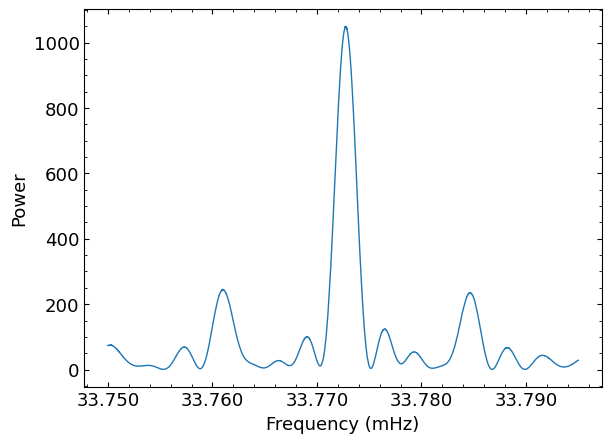

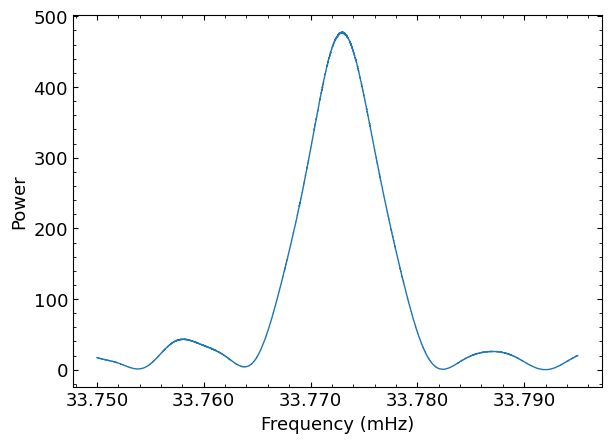

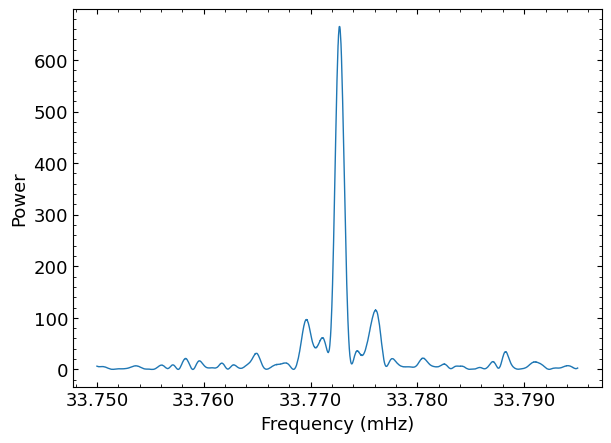

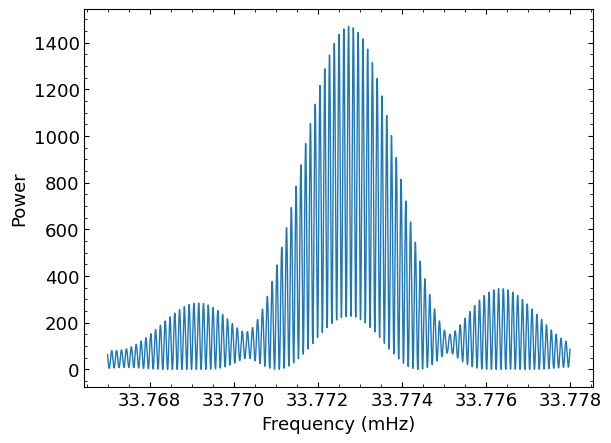

In [4]:
nharm = 1
results['table2'] = {}
for obs, name in labels.items():
    # The combined periodogram is shown over a narrower range to display its alias structure
    frequencies = np.linspace(0.033767, 0.033778, 4096) if obs == config.NICER_COMBINED else np.linspace(0.033750, 0.033795, 4096)
    frequency, power = z_n_search(events[obs]['total'].time, frequencies, nharm=nharm)
    peak_freq, peak_power = frequency[np.argmax(power)], power[np.argmax(power)]

    print(f'Observation {name}')
    f_lo, f_hi, _, _ = get_frequency_uncertainty(frequency, power, peak_freq, peak_power, nharm, 1)
    results['table2'][name] = {'peak_Hz': float(peak_freq), 'plus_Hz': float(f_hi - peak_freq), 'minus_Hz': float(peak_freq - f_lo), 'peak_power': float(peak_power)}

    plotting.plot_periodogram([{'frequency': frequency, 'power': power, 'lw': 1}], figsize=(6, 4.32), xfmt='%.3f', path=f'{savedir}/nicer_z2_{name}.pdf')

## Figure 9 (top right): high-resolution combined periodogram with the $2\sigma$ power threshold that selects the candidate aliases

Combined 2021 observation, high resolution
FREQUENCY RESULTS:
  Peak:        3.377273284624344e-02 Hz
  Uncertainty: +1.127940e-08 / -1.253267e-08 Hz

PERIOD RESULTS:
  Peak:        2.960968555765633e+01 s
  Uncertainty: +1.098782e-05 / -9.889027e-06 s


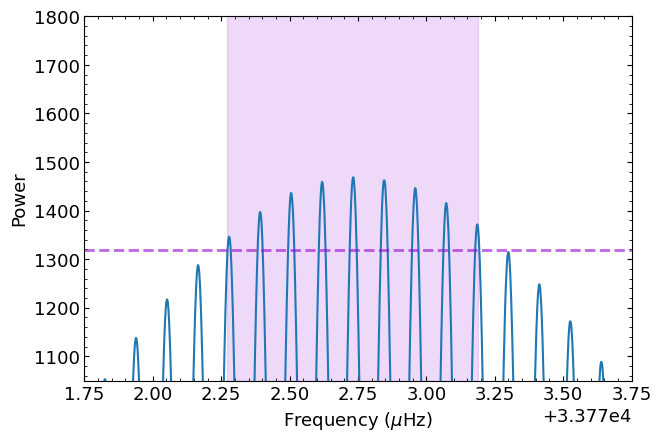

In [5]:
frequencies_hires = np.linspace(0.03376781252, 0.03377807803, 8192)
frequency_hires, power_hires = z_n_search(events[config.NICER_COMBINED]['total'].time, frequencies_hires, nharm=nharm)
peak_freq, peak_power = frequency_hires[np.argmax(power_hires)], power_hires[np.argmax(power_hires)]

print('Combined 2021 observation, high resolution')
f_lo, f_hi, power_threshold, _ = get_frequency_uncertainty(frequency_hires, power_hires, peak_freq, peak_power, nharm, 2)
results['combined_hires'] = {'peak_Hz': float(peak_freq), 'plus_Hz': float(f_hi - peak_freq), 'minus_Hz': float(peak_freq - f_lo), 'peak_power': float(peak_power)}

plotting.plot_hires_periodogram(frequency_hires, power_hires, power_threshold, path=f'{savedir}/nicer_z2_hires_2021.pdf')

## Fold the source and background light curves at the spin period (35 bins, phase zero at MJD 59230)

In [6]:
n_bins = 35
folded = {obs: {band: fold(events[obs][band], config.P_SPIN, config.FOLD_EPOCH_NICER, n_bins) for band in ['total', 'soft', 'hard']}
          for obs in config.NICER_OBS}
folded_bkg = {obs: {band: fold_lightcurve(bkg[obs][band], config.P_SPIN, config.FOLD_EPOCH_NICER, n_bins) for band in ['soft', 'hard']}
              for obs in config.NICER_OBS}

## Figure 2 (top row): background-subtracted soft (red) and hard (purple) profiles

In [7]:
profiles = {}
for obs, name in config.NICER_OBS.items():
    phase, _, soft_cr, soft_err, _ = folded[obs]['soft']
    _, _, hard_cr, hard_err, _ = folded[obs]['hard']
    _, _, soft_bkg, soft_bkg_err, _ = folded_bkg[obs]['soft']
    _, _, hard_bkg, hard_bkg_err, _ = folded_bkg[obs]['hard']
    soft_sub, soft_sub_err = soft_cr - soft_bkg, np.sqrt(soft_err**2 + soft_bkg_err**2)
    hard_sub, hard_sub_err = hard_cr - hard_bkg, np.sqrt(hard_err**2 + hard_bkg_err**2)
    profiles[obs] = (soft_sub, soft_sub_err, hard_sub, hard_sub_err)

    _, ext_phase = phase_centers(phase)
    plotting.plot_folded_profiles([
        (ext_phase, np.concatenate([soft_sub, soft_sub]), np.concatenate([soft_sub_err, soft_sub_err]), 'firebrick'),
        (ext_phase, np.concatenate([hard_sub, hard_sub]), np.concatenate([hard_sub_err, hard_sub_err]), 'darkviolet')],
        lw=2, alpha=0.35, ylim_top=1.1 * np.max(soft_sub), path=f'{savedir}/nicer_folded_softhard_{name}.pdf')

## Figure 3: hardness ratio of the 2024 profile, anticorrelated with the count rate

In [8]:
obs = '7656010100'
soft_sub, soft_sub_err, hard_sub, hard_sub_err = profiles[obs]
phase, _, total_cr, total_err, _ = folded[obs]['total']
_, _, soft_bkg, soft_bkg_err, _ = folded_bkg[obs]['soft']
_, _, hard_bkg, hard_bkg_err, _ = folded_bkg[obs]['hard']
total_sub = total_cr - soft_bkg - hard_bkg
total_sub_err = np.sqrt(total_err**2 + soft_bkg_err**2 + hard_bkg_err**2)
hr, hr_err = calculate_hardness_ratio(soft_sub, hard_sub, soft_sub_err, hard_sub_err)

_, ext_phase = phase_centers(phase)
plotting.plot_folded_hr(ext_phase, total_sub, total_sub_err, hr, hr_err, path=f'{savedir}/nicer_folded_hr_2024.pdf')

# Sinusoidal modulation of the hardness ratio (peak-to-peak amplitude quoted in Section 3)
hr_fit = test_hardness_ratio_variability(hr, hr_err)
amplitude, amplitude_err = hr_fit['fit_params'][1], hr_fit['fit_errors'][1]
results['hr_2024'] = {'amplitude': float(abs(amplitude)), 'amplitude_err': float(amplitude_err), 'peak_to_peak': float(2 * abs(amplitude))}


Model 1 (Constant): chi2 = 93.50, dof = 34, chi2_red = 2.75
Model 2 (Sinusoid): chi2 = 34.68, dof = 32, chi2_red = 1.08
  Offset: -0.3133 +/- 0.0049
  Amplitude: -0.0532 +/- 0.0069
  Phase shift: 0.137 cycles

F-test: F = 27.13, p = 1.28e-07, 5.3 sigma
Result: Sinusoid significantly better (p < 0.001)


## Figure 6: folded 2021A photon phases (0.4-2 keV) with the five-Gaussian template

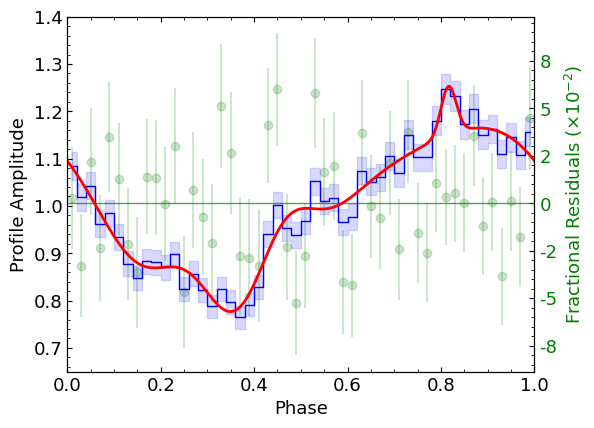

In [9]:
phases = np.load(config.TEMPLATE_PHASES)
primitives, norms = prim_io(config.TEMPLATE)
template = LCTemplate(primitives, norms)

plotting.plot_template(phases, template, nbins=50, path=f'{savedir}/nicer_2021a_phases_template.pdf')

## Save the numbers

In [10]:
with open(f'{config.RESULTS_DIR}/nicer_timing.json', 'w') as f:
    json.dump(results, f, indent=2)
print(json.dumps(results['table2'], indent=1))

{
 "2021a": {
  "peak_Hz": 0.033772725274725274,
  "plus_Hz": 3.73626373624536e-07,
  "minus_Hz": 3.076923076883453e-07,
  "peak_power": 1049.1703578127265
 },
 "2021b": {
  "peak_Hz": 0.033772923076923075,
  "plus_Hz": 1.373626373625536e-06,
  "minus_Hz": 1.2967032967034497e-06,
  "peak_power": 478.2183267027692
 },
 "2024": {
  "peak_Hz": 0.033772703296703295,
  "plus_Hz": 1.7582417582290288e-07,
  "minus_Hz": 1.5384615384417266e-07,
  "peak_power": 664.9366914748426
 },
 "2021combined": {
  "peak_Hz": 0.03377273235653236,
  "plus_Hz": 8.058608058636452e-09,
  "minus_Hz": 8.058608058636452e-09,
  "peak_power": 1468.7959388227075
 }
}
